# Лабораторная работа № 2. Классификация. Нейронные сети
## 1. Введение
**Цель:** изучить классификаторы Scikit-Learn и нейронные сети TensorFlow/Keras, подобрать гиперпараметры и освоить мониторинг TensorBoard.

Задача — предсказать уход клиента телекоммуникационной компании (Churn). Рассматриваются четыре варианта наивного Байеса и четыре других семейства: дерево решений, LDA, SVM и kNN. Для нейросети проводится отдельная серия контролируемых экспериментов.

Отчет содержит исполняемый код и реальные результаты. Положительный класс — `Churn=Yes` (1). Seed равен 42. Итоговые метрики считаются на общей отложенной выборке при пороге 0,5 (для SVM — штатный порог decision_function=0). Данные предоставлены в файле IBM Telco Customer Churn; это учебный анализ, а не доказательство причин оттока.

**Запуск:** расположите CSV в `data/` рядом с notebook и выполните все ячейки сверху вниз. Зависимости перечислены в `requirements-lab2.txt`. TensorBoard запускается командой из раздела 6. Перебор использует 3-fold CV и ограниченную сетку для разумного времени выполнения на CPU.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['OMP_NUM_THREADS'] = '2'
import json, random, shutil, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
SEED = 42
random.seed(SEED); np.random.seed(SEED)
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
print('Python:', platform.python_version(), 'NumPy:', np.__version__,
      'Pandas:', pd.__version__, 'Scikit-Learn:', sklearn.__version__)


Python: 3.12.14 NumPy: 2.3.5 Pandas: 2.2.3 Scikit-Learn: 1.8.0


## 2. Выбор и подготовка датасета
Одна строка соответствует клиенту. Цель `Churn` бинарная. `customerID` — идентификатор, исключается из обучения. Числовые признаки: срок обслуживания `tenure`, ежемесячные платежи `MonthlyCharges`, общие платежи `TotalCharges`. `SeniorCitizen` трактуется как бинарная категория. Остальные категории описывают пол, семью, услуги, договор и оплату.

В `TotalCharges` встречаются строки из пробелов: переводим их в NaN. Медиана и мода оцениваются **только на обучающих данных**, внутри Pipeline для каждого CV-фолда. Категории кодируются One-Hot, неизвестные категории допускаются. Пропуск услуги (`No internet service`) является отдельной категорией, а не NaN. Повторяющиеся идентификаторы проверяются явно.

Размер: (7043, 21) Дубликаты строк: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,тип,пропуски,уникальных
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


,число,доля
Churn,,
No,5174,0.73463
Yes,1869,0.26537


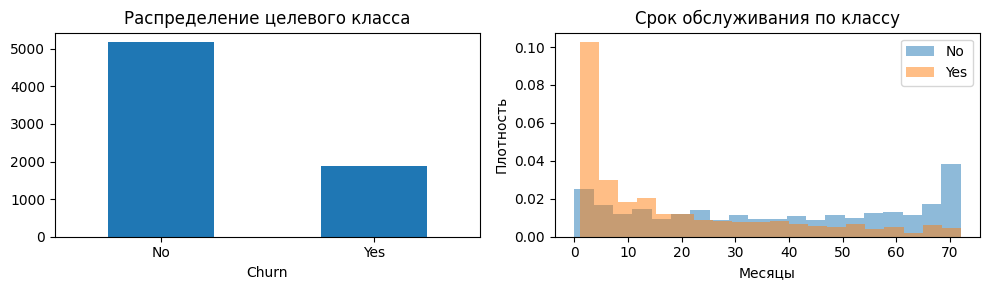

In [2]:
DATA = Path('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = pd.read_csv(DATA)
assert set(df.Churn.unique()) == {'Yes', 'No'}
assert df.customerID.is_unique, 'Обнаружены повторные клиенты: необходимо групповое разбиение'
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Размер:', df.shape, 'Дубликаты строк:', df.duplicated().sum())
display(df.head())
display(pd.DataFrame({'тип': df.dtypes.astype(str), 'пропуски': df.isna().sum(),
                      'уникальных': df.nunique()}))
display(df.Churn.value_counts().rename('число').to_frame().assign(доля=df.Churn.value_counts(normalize=True)))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df.Churn.value_counts().plot.bar(ax=ax[0], title='Распределение целевого класса', rot=0)
for label, group in df.groupby('Churn'):
    ax[1].hist(group.tenure, bins=20, alpha=.5, label=label, density=True)
ax[1].set(title='Срок обслуживания по классу', xlabel='Месяцы', ylabel='Плотность'); ax[1].legend()
plt.tight_layout(); plt.show()


## 3. Разбиение выборки и протокол оценки
Стратифицированное разбиение 80/20 сохраняет доли классов. Тест не участвует в выборе параметров. Для классических моделей используется 3-кратная стратифицированная кросс-валидация на 80% данных с выбором по среднему ROC-AUC. Для нейросети из обучающей части дополнительно выделяются 20% на валидацию (итого примерно 64/16/20%).

Accuracy — доля правильных ответов; Precision = TP/(TP+FP); Recall = TP/(TP+FN); F1 = 2PR/(P+R). ROC-AUC измеряет качество ранжирования по всем порогам. При дисбалансе высокая Accuracy сама по себе недостаточна, поэтому добавлена модель, всегда выбирающая большинство. Метрики Precision/Recall/F1 относятся к уходящим клиентам.

In [3]:
X = df.drop(columns=['customerID', 'Churn'])
y = df.Churn.map({'No': 0, 'Yes': 1})
num = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat = [c for c in X.columns if c not in num]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.2, stratify=y_train, random_state=SEED)
display(pd.DataFrame({'набор':['train (CV)', 'NN fit', 'NN validation', 'test'],
    'объектов':[len(y_train),len(y_fit),len(y_val),len(y_test)],
    'доля Churn':[y_train.mean(),y_fit.mean(),y_val.mean(),y_test.mean()]}))
def preprocessing(kind='standard'):
    # clip исключает отрицательные значения при выходе за train-диапазон для Multinomial/Complement NB.
    scaler = StandardScaler() if kind == 'standard' else MinMaxScaler(clip=True)
    return ColumnTransformer([
        ('num', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',scaler)]), num),
        ('cat', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                         ('onehot',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)
    ], sparse_threshold=0)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


,набор,объектов,доля Churn
0,train (CV),5634,0.265353
1,NN fit,4507,0.265365
2,NN validation,1127,0.265306
3,test,1409,0.265436


## 4. Методы классификации
- **GaussianNB:** условно независимые признаки, нормальные распределения внутри класса. Категории One-Hot не являются нормальными, поэтому предположение приблизительное.
- **MultinomialNB:** неотрицательные признаки, исходно частоты событий. Здесь проверяется как учебный вариант на MinMax + One-Hot; непрерывные платежи не являются счетчиками.
- **ComplementNB:** использует статистики дополнения класса; часто полезен для дисбалансных текстовых данных. Применимость здесь также проверяется эмпирически.
- **BernoulliNB:** бинарные признаки. Числовые признаки MinMax бинаризуются порогом 0,5 внутри модели; информация о величинах частично теряется.
- **Дерево решений:** последовательные пороговые разбиения; глубина и минимальный лист ограничивают переобучение.
- **LDA:** линейная граница при общей внутриклассовой ковариации; shrinkage стабилизирует оценку при зависимых One-Hot столбцах.
- **SVM:** максимизация зазора, параметр C задает штраф ошибок, RBF-ядро позволяет нелинейную границу; gamma задает локальность.
- **kNN:** голосование ближайших объектов; k регулирует сглаживание, масштабирование числовых признаков обязательно.

## 5. Настройка гиперпараметров
Ниже указаны все проверяемые значения. Для каждого классификатора сохраняются исходная модель с параметрами, заданными в specs до перебора и лучшая модель по CV ROC-AUC. Сравнение исходной и настроенной модели проводится на одинаковых фолдах. В таблицах приведены среднее и стандартное отклонение по фолдам; это не доверительный интервал. Пространство параметров ограничено и не гарантирует глобальный оптимум.

GaussianNB best CV AUC: 0.8196 {'model__var_smoothing': 1e-05}


,params,mean_train_score,mean_test_score,std_test_score
3,{'model__var_smoothing': 1e-05},0.820677,0.819555,0.003605
0,{'model__var_smoothing': 1e-11},0.820677,0.819554,0.003604
1,{'model__var_smoothing': 1e-09},0.820677,0.819554,0.003604
2,{'model__var_smoothing': 1e-07},0.820677,0.819554,0.003604


MultinomialNB best CV AUC: 0.8202 {'model__alpha': 0.01}


,params,mean_train_score,mean_test_score,std_test_score
0,{'model__alpha': 0.01},0.821232,0.820169,0.004269
1,{'model__alpha': 0.1},0.821232,0.820164,0.004266
2,{'model__alpha': 1.0},0.821231,0.820149,0.004270
3,{'model__alpha': 10.0},0.821162,0.820130,0.004223


ComplementNB best CV AUC: 0.8202 {'model__alpha': 0.01, 'model__norm': False}


,params,mean_train_score,mean_test_score,std_test_score
0,"{'model__alpha': 0.01, 'model__norm': False}",0.821232,0.820169,0.004269
2,"{'model__alpha': 0.1, 'model__norm': False}",0.821232,0.820164,0.004266
4,"{'model__alpha': 1.0, 'model__norm': False}",0.821231,0.820149,0.004270
6,"{'model__alpha': 10.0, 'model__norm': False}",0.821162,0.820130,0.004223
3,"{'model__alpha': 0.1, 'model__norm': True}",0.819996,0.818951,0.004270
1,"{'model__alpha': 0.01, 'model__norm': True}",0.819995,0.818944,0.004269
5,"{'model__alpha': 1.0, 'model__norm': True}",0.819987,0.818930,0.004269
7,"{'model__alpha': 10.0, 'model__norm': True}",0.819966,0.818888,0.004281


... (7 outputs left out)

,params,mean_train_score,mean_test_score,std_test_score
4,"{'model__C': 0.1, 'model__gamma': 0.01, 'model...",0.839906,0.837609,0.006739
6,"{'model__C': 1.0, 'model__gamma': 0.01, 'model...",0.842137,0.835869,0.007251
0,"{'model__C': 0.1, 'model__kernel': 'linear'}",0.837935,0.834289,0.006514
1,"{'model__C': 1.0, 'model__kernel': 'linear'}",0.837490,0.833737,0.006809
2,"{'model__C': 10.0, 'model__kernel': 'linear'}",0.837520,0.833668,0.006523
8,"{'model__C': 10.0, 'model__gamma': 0.01, 'mode...",0.843768,0.819321,0.007916
3,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo...",0.835377,0.819125,0.010444
5,"{'model__C': 1.0, 'model__gamma': 'scale', 'mo...",0.867878,0.798008,0.007039
7,"{'model__C': 10.0, 'model__gamma': 'scale', 'm...",0.936454,0.783310,0.005260


kNN best CV AUC: 0.8363 {'model__n_neighbors': 65, 'model__weights': 'uniform'}


,params,mean_train_score,mean_test_score,std_test_score
6,"{'model__n_neighbors': 65, 'model__weights': '...",0.847188,0.836343,0.005897
4,"{'model__n_neighbors': 35, 'model__weights': '...",0.853886,0.832815,0.006357
7,"{'model__n_neighbors': 65, 'model__weights': '...",0.999994,0.824592,0.007378
2,"{'model__n_neighbors': 15, 'model__weights': '...",0.866924,0.823099,0.006408
5,"{'model__n_neighbors': 35, 'model__weights': '...",0.999994,0.819025,0.007337
3,"{'model__n_neighbors': 15, 'model__weights': '...",0.999994,0.806310,0.007453
0,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.900057,0.775385,0.004247
1,"{'model__n_neighbors': 5, 'model__weights': 'd...",0.999994,0.762981,0.006235


,Метод,Исходный CV AUC,Лучший CV AUC,Изменение,Параметры
0,GaussianNB,0.819554,0.819555,0.000001,{'model__var_smoothing': 1e-05}
1,MultinomialNB,0.820149,0.820169,0.000020,{'model__alpha': 0.01}
2,ComplementNB,0.820149,0.820169,0.000020,"{'model__alpha': 0.01, 'model__norm': False}"
3,BernoulliNB,0.818729,0.820558,0.001830,"{'model__alpha': 10.0, 'model__binarize': 0.25}"
4,DecisionTree,0.656702,0.832808,0.176107,"{'model__max_depth': 6, 'model__min_samples_le..."
5,LDA,0.838534,0.841037,0.002502,{'model__shrinkage': 0.5}
6,SVM,0.798008,0.837609,0.039601,"{'model__C': 0.1, 'model__gamma': 0.01, 'model..."
7,kNN,0.775385,0.836343,0.060958,"{'model__n_neighbors': 65, 'model__weights': '..."


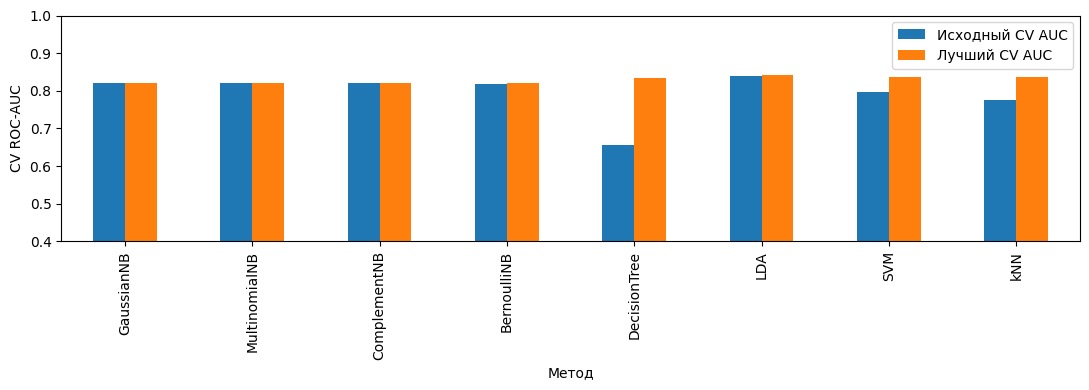

In [4]:
specs = {
 'GaussianNB': (GaussianNB(), {'model__var_smoothing':[1e-11,1e-9,1e-7,1e-5]}, 'standard'),
 'MultinomialNB': (MultinomialNB(), {'model__alpha':[.01,.1,1.,10.]}, 'minmax'),
 'ComplementNB': (ComplementNB(), {'model__alpha':[.01,.1,1.,10.], 'model__norm':[False,True]}, 'minmax'),
 'BernoulliNB': (BernoulliNB(binarize=.5), {'model__alpha':[.1,1.,10.], 'model__binarize':[.25,.5,.75]}, 'minmax'),
 'DecisionTree': (DecisionTreeClassifier(random_state=SEED),
     {'model__max_depth':[3,6,None], 'model__min_samples_leaf':[1,20,50]}, 'standard'),
 'LDA': (LinearDiscriminantAnalysis(solver='lsqr'), {'model__shrinkage':[None,'auto',.1,.5]}, 'standard'),
 'SVM': (SVC(), [{'model__kernel':['linear'], 'model__C':[.1,1.,10.]},
                {'model__kernel':['rbf'], 'model__C':[.1,1.,10.], 'model__gamma':['scale',.01]}], 'standard'),
 'kNN': (KNeighborsClassifier(n_jobs=1), {'model__n_neighbors':[5,15,35,65],
                                       'model__weights':['uniform','distance']}, 'standard')
}
searches, baselines, cv_tables = {}, {}, []
for name, (model, grid, kind) in specs.items():
    pipe = Pipeline([('prep',preprocessing(kind)),('model',model)])
    # Тот же CV-протокол, одна конфигурация исходных параметров.
    base = GridSearchCV(pipe, {}, scoring='roc_auc', cv=cv, n_jobs=2, error_score='raise')
    base.fit(X_train, y_train); baselines[name] = base
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=cv, n_jobs=2,
                          return_train_score=True, error_score='raise')
    search.fit(X_train, y_train); searches[name] = search
    table = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
    table['method'] = name; cv_tables.append(table)
    print(name, 'best CV AUC:', round(search.best_score_,4), search.best_params_)
    display(table[['params','mean_train_score','mean_test_score','std_test_score']])
cv_all = pd.concat(cv_tables, ignore_index=True)
cv_all.to_csv(ART/'cv_results.csv', index=False)
cv_summary = pd.DataFrame([{'Метод':name,'Исходный CV AUC':baselines[name].best_score_,
                            'Лучший CV AUC':s.best_score_,
                            'Изменение':s.best_score_-baselines[name].best_score_,
                            'Параметры':str(s.best_params_)} for name,s in searches.items()])
display(cv_summary)
cv_summary.plot.bar(x='Метод', y=['Исходный CV AUC','Лучший CV AUC'], figsize=(11,4), ylim=(.4,1))
plt.ylabel('CV ROC-AUC'); plt.tight_layout(); plt.show()


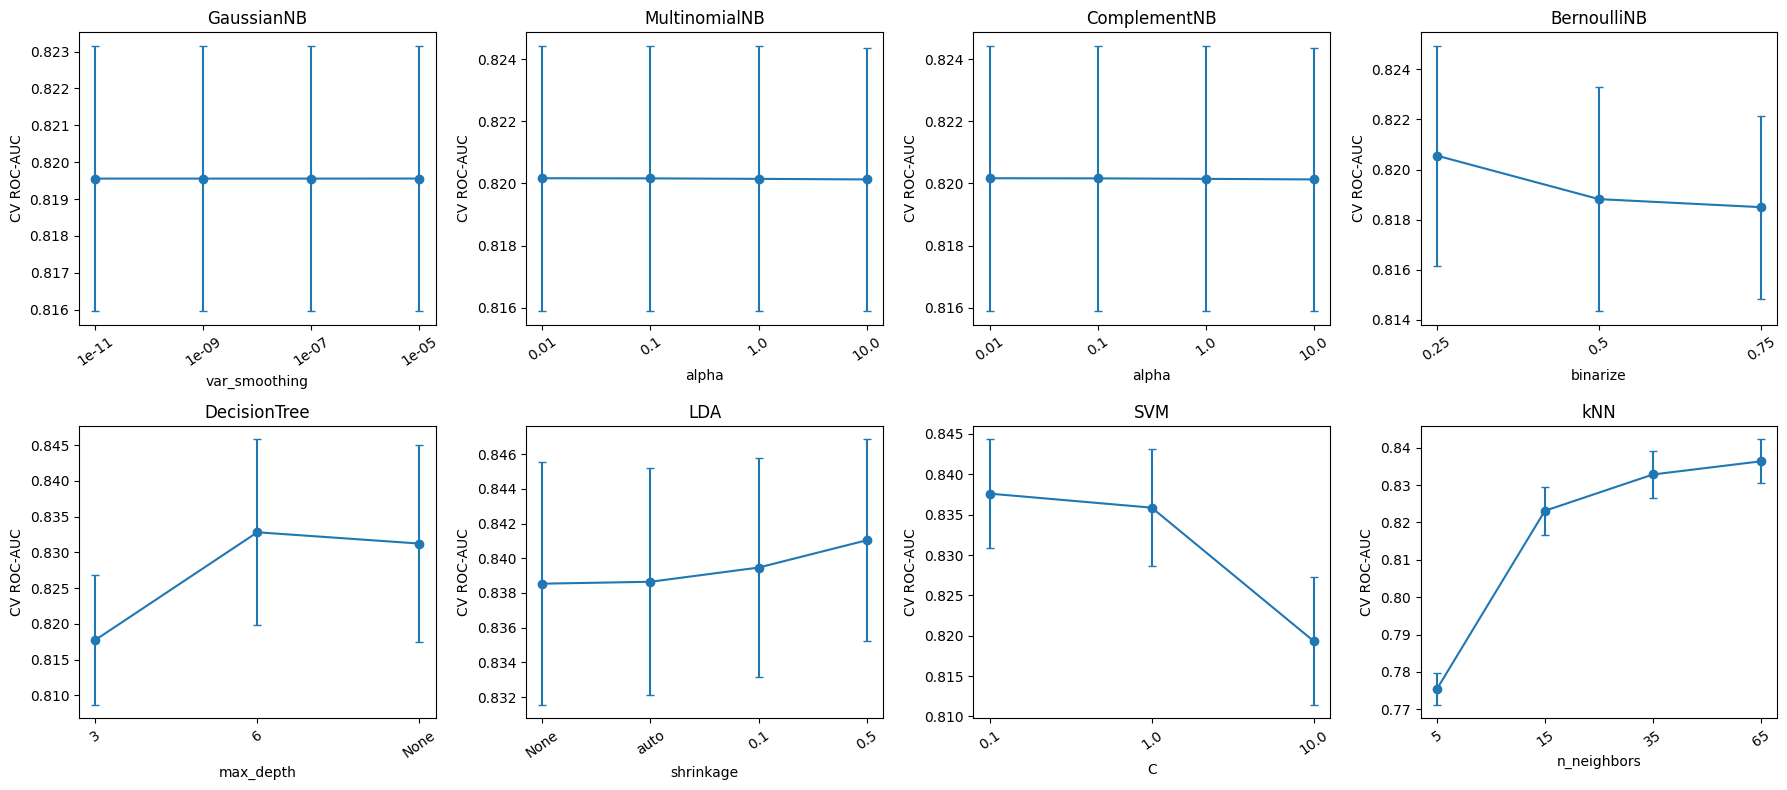

**GaussianNB:** диапазон среднего CV AUC 0.8196–0.8196; лучший вариант `{'model__var_smoothing': 1e-05}`. Разрыв train−CV для него 0.0011. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**MultinomialNB:** диапазон среднего CV AUC 0.8201–0.8202; лучший вариант `{'model__alpha': 0.01}`. Разрыв train−CV для него 0.0011. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**ComplementNB:** диапазон среднего CV AUC 0.8189–0.8202; лучший вариант `{'model__alpha': 0.01, 'model__norm': False}`. Разрыв train−CV для него 0.0011. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**BernoulliNB:** диапазон среднего CV AUC 0.8185–0.8206; лучший вариант `{'model__alpha': 10.0, 'model__binarize': 0.25}`. Разрыв train−CV для него 0.0009. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**DecisionTree:** диапазон среднего CV AUC 0.6567–0.8328; лучший вариант `{'model__max_depth': 6, 'model__min_samples_leaf': 50}`. Разрыв train−CV для него 0.0297. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**LDA:** диапазон среднего CV AUC 0.8385–0.8410; лучший вариант `{'model__shrinkage': 0.5}`. Разрыв train−CV для него 0.0021. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**SVM:** диапазон среднего CV AUC 0.7833–0.8376; лучший вариант `{'model__C': 0.1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}`. Разрыв train−CV для него 0.0023. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

**kNN:** диапазон среднего CV AUC 0.7630–0.8363; лучший вариант `{'model__n_neighbors': 65, 'model__weights': 'uniform'}`. Разрыв train−CV для него 0.0108. Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.

In [5]:
# Изолируем влияние одного параметра: остальные фиксируются лучшей конфигурацией.
from sklearn.model_selection import ParameterGrid
fig, axes = plt.subplots(2,4,figsize=(18,8))
focus = ['var_smoothing','alpha','alpha','binarize','max_depth','shrinkage','C','n_neighbors']
for ax, (name, search), param in zip(axes.ravel(), searches.items(), focus):
    t = pd.DataFrame(search.cv_results_)
    key = 'model__'+param
    mask = [all(p.get(k)==v for k,v in search.best_params_.items() if k != key) for p in t.params]
    t = t.loc[mask]
    labels = [str(p.get(key)) for p in t.params]
    ax.errorbar(range(len(t)),t.mean_test_score,yerr=t.std_test_score, marker='o',capsize=3)
    ax.set_xticks(range(len(t)),labels,rotation=35)
    ax.set(title=name, xlabel=param, ylabel='CV ROC-AUC')
plt.tight_layout(); plt.show()
for name, s in searches.items():
    t = pd.DataFrame(s.cv_results_)
    gap = t.loc[s.best_index_,'mean_train_score'] - s.best_score_
    display(Markdown(f'**{name}:** диапазон среднего CV AUC {t.mean_test_score.min():.4f}–{t.mean_test_score.max():.4f}; '
                     f'лучший вариант `{s.best_params_}`. Разрыв train−CV для него {gap:.4f}. '
                     'Большой положительный разрыв указывает на возможное переобучение; малые различия относительно разброса фолдов не следует переоценивать.'))


## 6. Нейронная сеть TensorFlow и TensorBoard
Полносвязная сеть для табличных данных. Базовая архитектура: вход после StandardScaler и One-Hot → Dense(32, ReLU) → Dense(1, sigmoid). Выход — оценка вероятности оттока. Потери: binary cross-entropy; оптимизатор Adam, learning rate = 0,001. Размер батча по умолчанию 32.

В экспериментах относительно базы меняется **один фактор**: максимум эпох (10, 30, 60), батч (32/128), число нейронов (32/64), число скрытых слоев (1/2), активация (ReLU/tanh). EarlyStopping по validation loss с patience=7 восстанавливает лучшие веса, поэтому фактическое число эпох может быть меньше лимита. Веса классов и порог не подбираются. Для честной валидации нейросетевой препроцессор обучается только на NN fit. Выбор конфигурации — по validation ROC-AUC после восстановления весов, без просмотра теста. Один seed обеспечивает контролируемое сравнение, но не заменяет многократные прогоны.

TensorBoard callback записывает loss, accuracy, AUC и их validation-аналоги. Истории также выводятся графиками непосредственно в отчете.

In [6]:
import tensorflow as tf
print('TensorFlow:', tf.__version__)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
prep_nn = preprocessing()
a_fit = prep_nn.fit_transform(X_fit).astype('float32')
a_val = prep_nn.transform(X_val).astype('float32')
a_test = prep_nn.transform(X_test).astype('float32')
def dataset(a, b=None, batch=32, training=False):
    d = tf.data.Dataset.from_tensor_slices(a if b is None else (a,np.asarray(b,dtype='float32')))
    if training: d = d.shuffle(len(a),seed=SEED)
    opts = tf.data.Options(); opts.threading.private_threadpool_size=1
    return d.batch(batch).with_options(opts)
configs = [
 {'name':'base','units':[32],'activation':'relu','batch':32,'epochs':30},
 {'name':'epochs10','units':[32],'activation':'relu','batch':32,'epochs':10},
 {'name':'epochs60','units':[32],'activation':'relu','batch':32,'epochs':60},
 {'name':'batch128','units':[32],'activation':'relu','batch':128,'epochs':30},
 {'name':'units64','units':[64],'activation':'relu','batch':32,'epochs':30},
 {'name':'two_layers','units':[32,32],'activation':'relu','batch':32,'epochs':30},
 {'name':'tanh','units':[32],'activation':'tanh','batch':32,'epochs':30}]
# Новая папка исключает смешивание событий с предыдущим выполнением.
from datetime import datetime, timezone
LOGROOT = Path('logs') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
nn_models, histories, nn_rows = {}, {}, []
for cfg in configs:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([tf.keras.Input(shape=(a_fit.shape[1],))] +
        [tf.keras.layers.Dense(u,activation=cfg['activation']) for u in cfg['units']] +
        [tf.keras.layers.Dense(1,activation='sigmoid')])
    model.compile(optimizer=tf.keras.optimizers.Adam(.001), loss='binary_crossentropy',
                  metrics=['accuracy',tf.keras.metrics.AUC(name='auc')])
    history = model.fit(dataset(a_fit,y_fit,cfg['batch'],True),
        validation_data=dataset(a_val,y_val,128), epochs=cfg['epochs'], verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True),
                   tf.keras.callbacks.TensorBoard(log_dir=str(LOGROOT/cfg['name']), histogram_freq=0)])
    prob = model.predict(dataset(a_val,batch=128),verbose=0).ravel()
    nn_models[cfg['name']] = model; histories[cfg['name']] = history.history
    nn_rows.append({**cfg,'actual_epochs':len(history.history['loss']),
                    'best_loss_epoch':int(np.argmin(history.history['val_loss']))+1,
                    'val_auc':roc_auc_score(y_val,prob),
                    'val_f1':f1_score(y_val,prob>=.5)})
    print(cfg['name'], 'epochs:', nn_rows[-1]['actual_epochs'], 'val AUC:',round(nn_rows[-1]['val_auc'],4))
nn_results = pd.DataFrame(nn_rows)
display(nn_results)
nn_results.to_csv(ART/'nn_experiments.csv',index=False)
best_nn_name = nn_results.sort_values('val_auc',ascending=False).iloc[0]['name']
best_nn = nn_models[best_nn_name]
print('Выбрана по validation ROC-AUC:', best_nn_name)
best_nn.summary()
best_nn.save(ART/'best_nn.keras')
with open(ART/'histories.json','w') as f: json.dump(histories,f)


TensorFlow: 2.20.0


/workspace/lab2-venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


base epochs: 17 val AUC: 0.8497


/workspace/lab2-venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


epochs10 epochs: 10 val AUC: 0.8497


/workspace/lab2-venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (13 outputs left out)

 Total params: 4,613 (18.02 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,076 (12.02 KB)

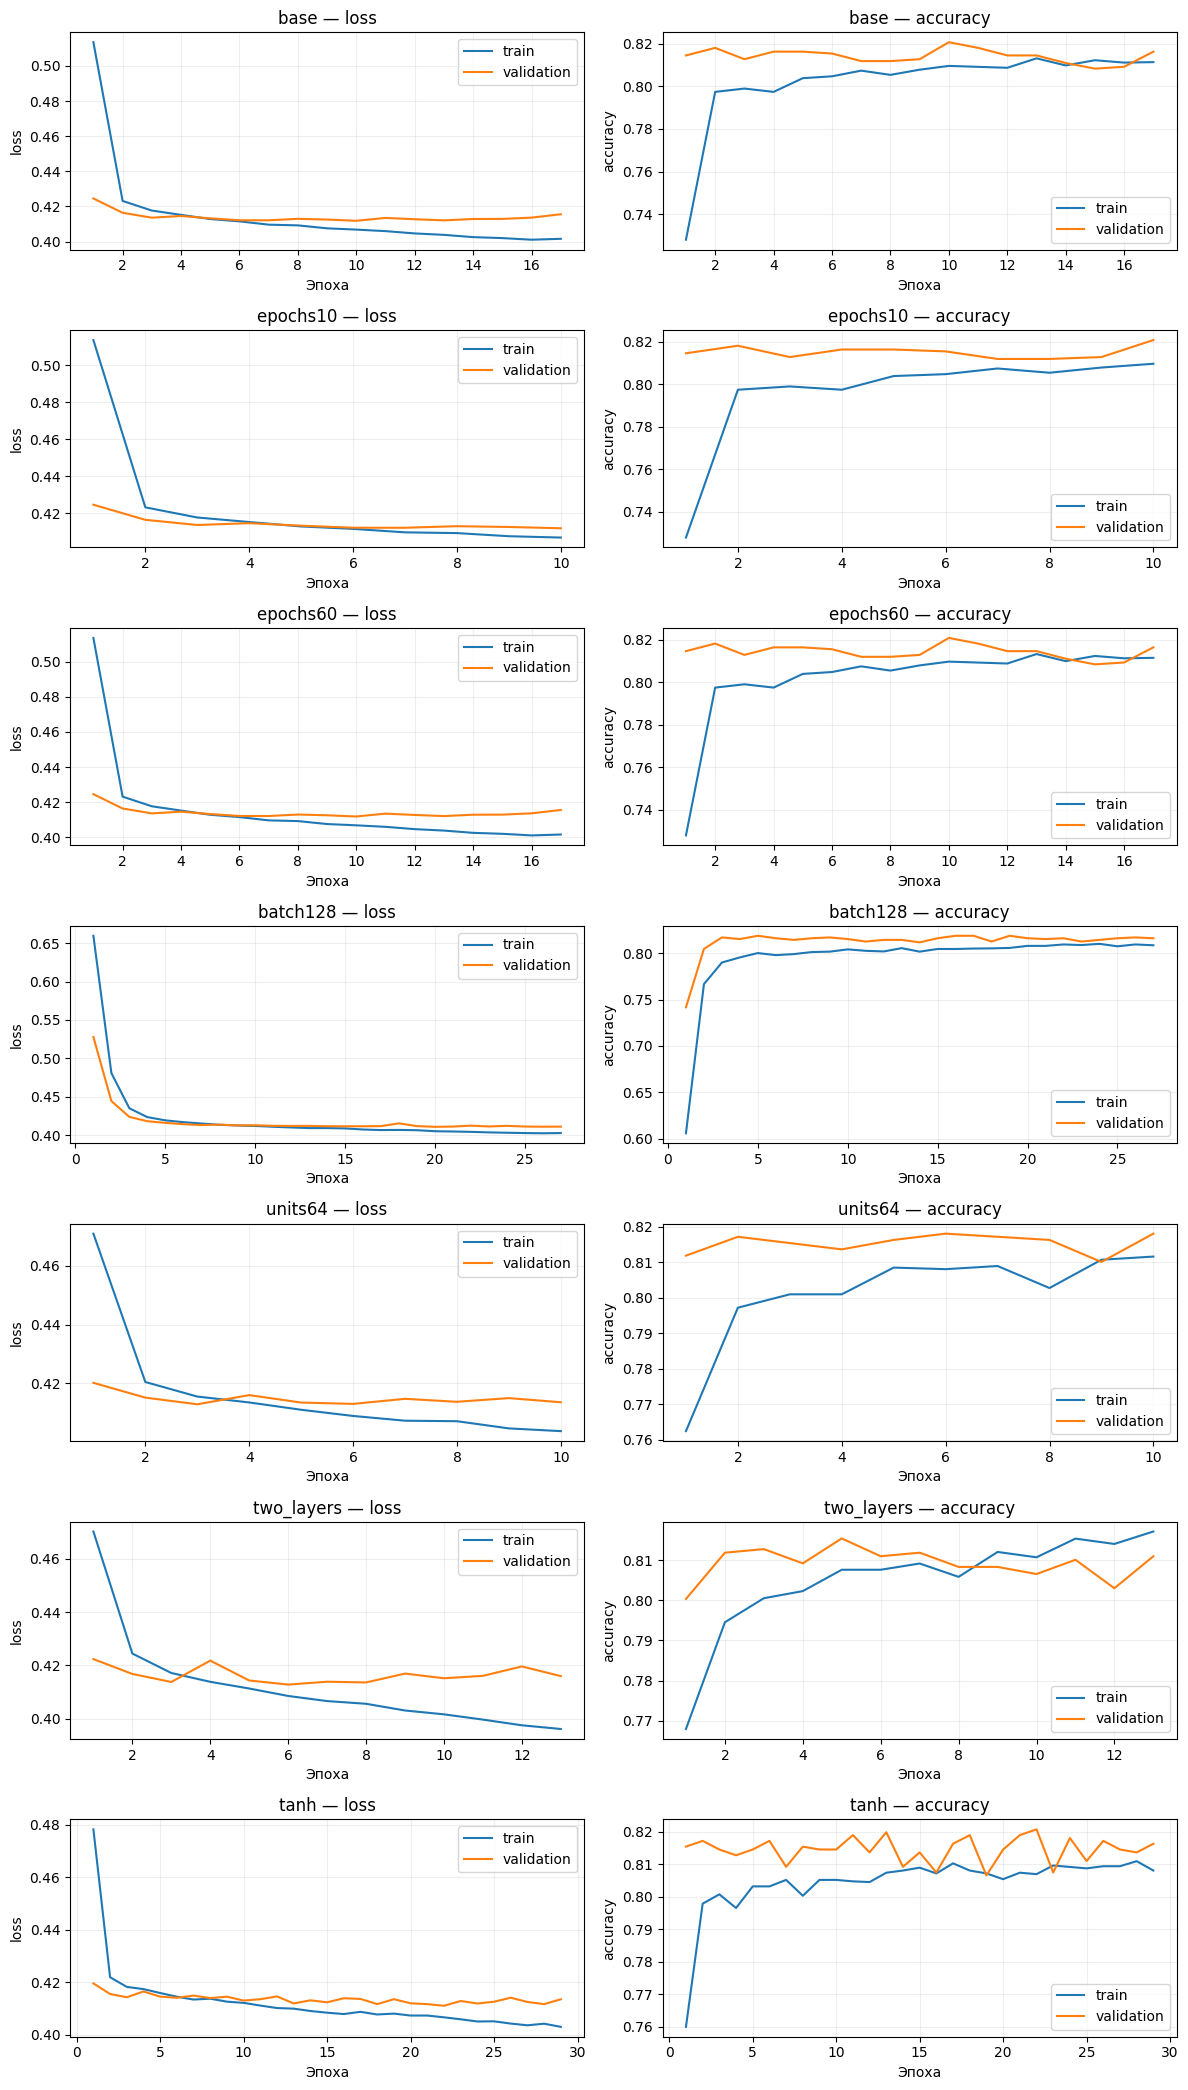

**base**: validation AUC=0.8497, изменение к базе +0.0000; выполнено 17 эпох, минимум validation loss на эпохе 10.

**epochs10**: validation AUC=0.8497, изменение к базе +0.0000; выполнено 10 эпох, минимум validation loss на эпохе 10.

**epochs60**: validation AUC=0.8497, изменение к базе +0.0000; выполнено 17 эпох, минимум validation loss на эпохе 10.

**batch128**: validation AUC=0.8499, изменение к базе +0.0003; выполнено 27 эпох, минимум validation loss на эпохе 20.

**units64**: validation AUC=0.8483, изменение к базе -0.0014; выполнено 10 эпох, минимум validation loss на эпохе 3.

**two_layers**: validation AUC=0.8487, изменение к базе -0.0009; выполнено 13 эпох, минимум validation loss на эпохе 6.

**tanh**: validation AUC=0.8511, изменение к базе +0.0014; выполнено 29 эпох, минимум validation loss на эпохе 22.

In [7]:
fig, axes = plt.subplots(len(configs),2,figsize=(12,3*len(configs)))
for row,cfg in enumerate(configs):
    h = histories[cfg['name']]
    for col,metric in enumerate(['loss','accuracy']):
        epochs = np.arange(1,len(h[metric])+1)
        axes[row,col].plot(epochs,h[metric],label='train')
        axes[row,col].plot(epochs,h['val_'+metric],label='validation')
        axes[row,col].set(title=cfg['name']+' — '+metric,xlabel='Эпоха',ylabel=metric)
        axes[row,col].legend(); axes[row,col].grid(alpha=.2)
plt.tight_layout(); plt.show()
base_auc = nn_results.set_index('name').loc['base','val_auc']
for _,r in nn_results.iterrows():
    display(Markdown(f"**{r['name']}**: validation AUC={r.val_auc:.4f}, изменение к базе {r.val_auc-base_auc:+.4f}; "
                     f"выполнено {r.actual_epochs} эпох, минимум validation loss на эпохе {r.best_loss_epoch}."))


### Мониторинг TensorBoard
Для интерактивного просмотра в Jupyter выполните в отдельной ячейке:
```python
%load_ext tensorboard
%tensorboard --logdir logs
```
Или в терминале из каталога отчета: `tensorboard --logdir logs --port 6006`.
Вкладка Scalars показывает кривые обучения и валидации для каждой конфигурации. Увеличение train accuracy при ухудшении validation loss — признак переобучения. Ниже проверяется, что журналы действительно содержат скаляры текущего запуска; интерактивный интерфейс не требуется для чтения отчета.

In [8]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
log_check = []
for event in LOGROOT.rglob('events.out.tfevents.*'):
    acc = EventAccumulator(str(event)); acc.Reload()
    tags = acc.Tags()
    log_check.append({'файл':str(event),'скаляры':tags['scalars'],'тензоры':tags['tensors']})
assert log_check, 'Журналы TensorBoard не созданы'
assert any('epoch_loss' in r['тензоры'] or 'epoch_loss' in r['скаляры'] for r in log_check)
display(pd.DataFrame(log_check))


,файл,скаляры,тензоры
0,logs/20261102T111603394057Z/units64/validation...,[],"[evaluation_accuracy_vs_iterations, evaluation..."
1,logs/20261102T111603394057Z/units64/train/even...,[],"[keras, epoch_accuracy, epoch_auc, epoch_loss,..."
2,logs/20261102T111603394057Z/epochs60/validatio...,[],"[evaluation_accuracy_vs_iterations, evaluation..."
3,logs/20261102T111603394057Z/epochs60/train/eve...,[],"[keras, epoch_accuracy, epoch_auc, epoch_loss,..."
4,logs/20261102T111603394057Z/base/validation/ev...,[],"[evaluation_accuracy_vs_iterations, evaluation..."
5,logs/20261102T111603394057Z/base/train/events....,[],"[keras, epoch_accuracy, epoch_auc, epoch_loss,..."
6,logs/20261102T111603394057Z/batch128/validatio...,[],"[evaluation_accuracy_vs_iterations, evaluation..."
7,logs/20261102T111603394057Z/batch128/train/eve...,[],"[keras, epoch_accuracy, epoch_auc, epoch_loss,..."
8,logs/20261102T111603394057Z/two_layers/validat...,[],"[evaluation_accuracy_vs_iterations, evaluation..."
9,logs/20261102T111603394057Z/two_layers/train/e...,[],"[keras, epoch_accuracy, epoch_auc, epoch_loss,..."


## 7. Сравнительный анализ
Все модели заморожены до вычисления тестовых метрик. Для ROC используется predict_proba, а для SVM — decision_function (для ROC-AUC калиброванные вероятности не обязательны). Нейросеть остается обученной на NN fit с выбранными по validation весами; классические модели переобучены GridSearchCV на полном train. Это сравнение законченных протоколов с разными объемами обучения; различие учитывается при интерпретации.

Показаны исходные и настроенные модели, контроль большинства и выбранная нейросеть. Настроенные модели выбраны по CV, нейросеть — по validation. Рейтинг на test является описательным итогом, а не новым этапом подбора.

,Метод,Вариант,Accuracy,Precision,Recall,F1,ROC-AUC
0,GaussianNB,исходная,0.6955,0.4597,0.8396,0.5941,0.8075
1,GaussianNB,настроенная,0.6955,0.4597,0.8396,0.5941,0.8075
2,MultinomialNB,исходная,0.7090,0.4716,0.7995,0.5933,0.8066
3,MultinomialNB,настроенная,0.7090,0.4716,0.7995,0.5933,0.8066
4,ComplementNB,исходная,0.6778,0.4438,0.8449,0.5820,0.8066
5,ComplementNB,настроенная,0.6785,0.4444,0.8449,0.5825,0.8066
6,BernoulliNB,исходная,0.7182,0.4815,0.7995,0.6010,0.8069
7,BernoulliNB,настроенная,0.7133,0.4759,0.7914,0.5944,0.8088
8,DecisionTree,исходная,0.7253,0.4834,0.5053,0.4941,0.6549
9,DecisionTree,настроенная,0.7949,0.6580,0.4733,0.5505,0.8326


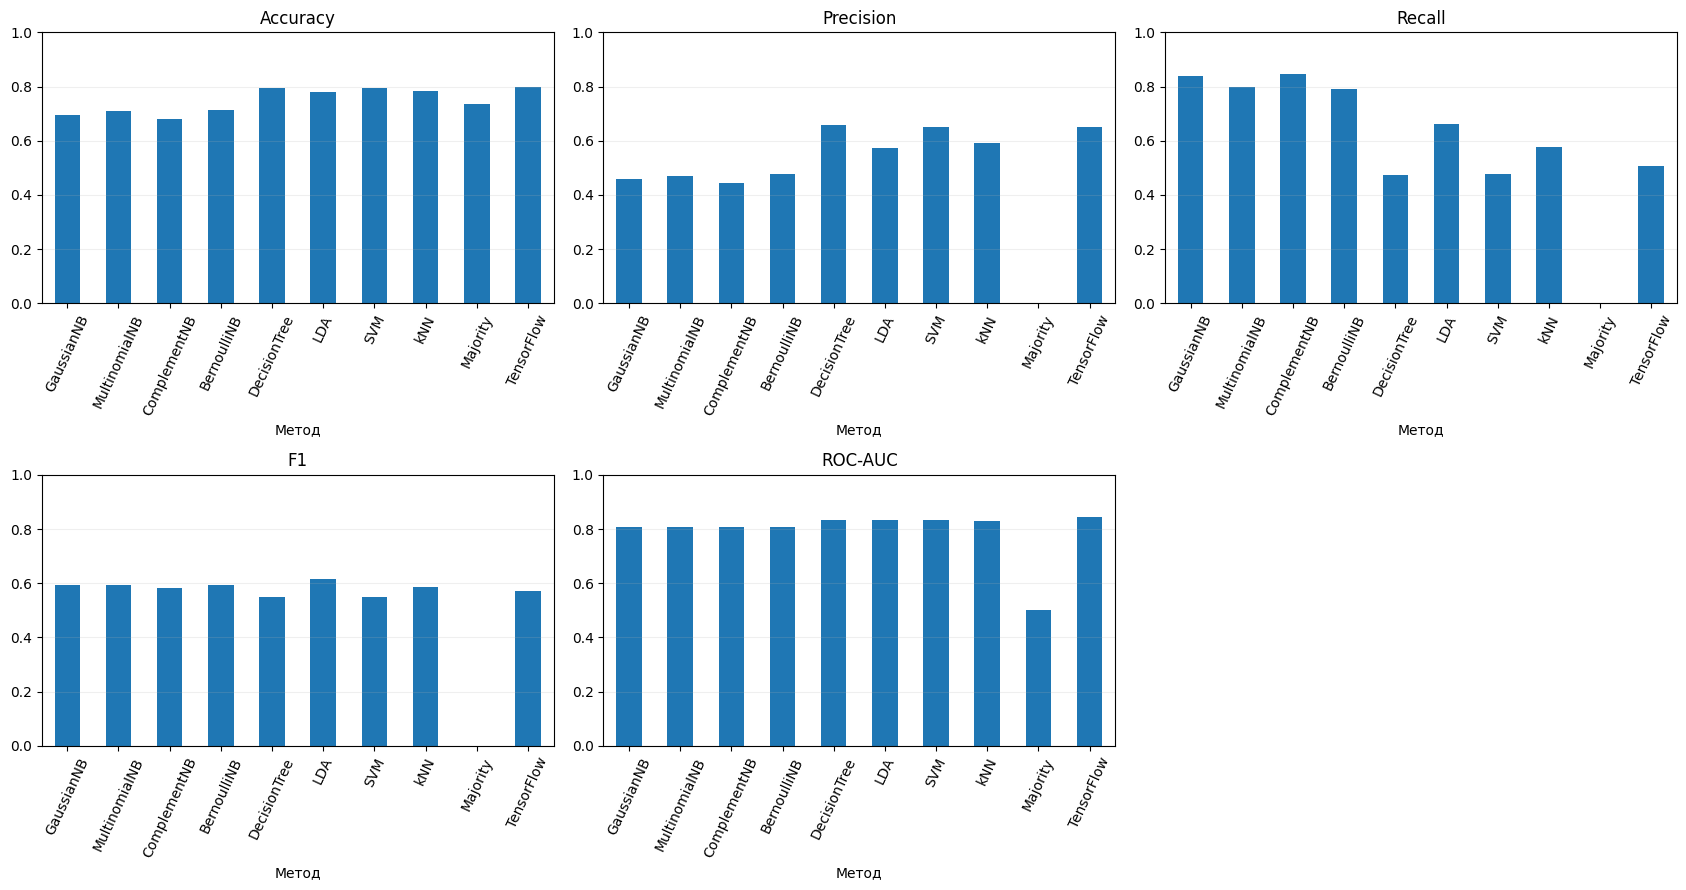

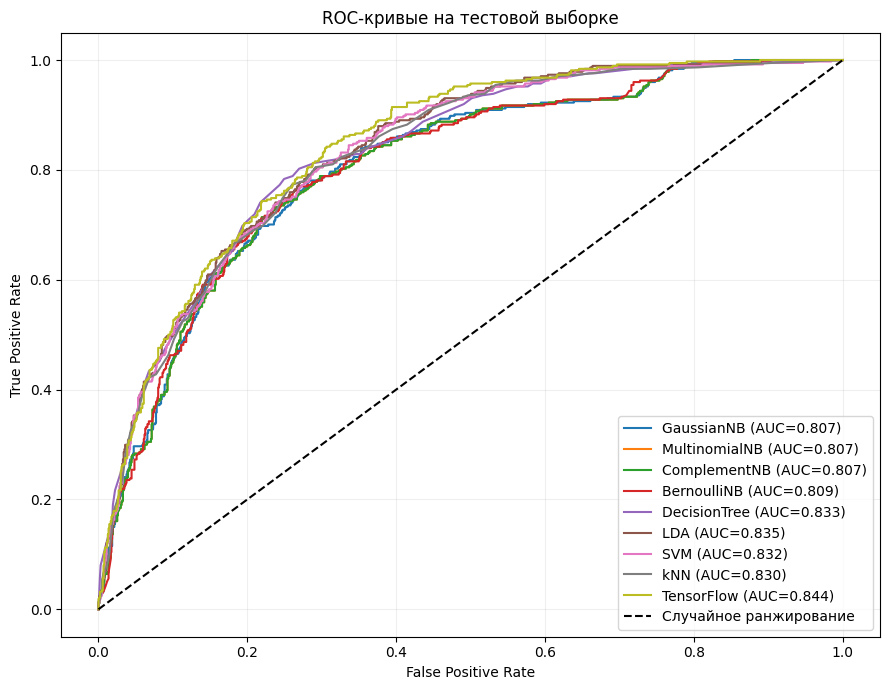

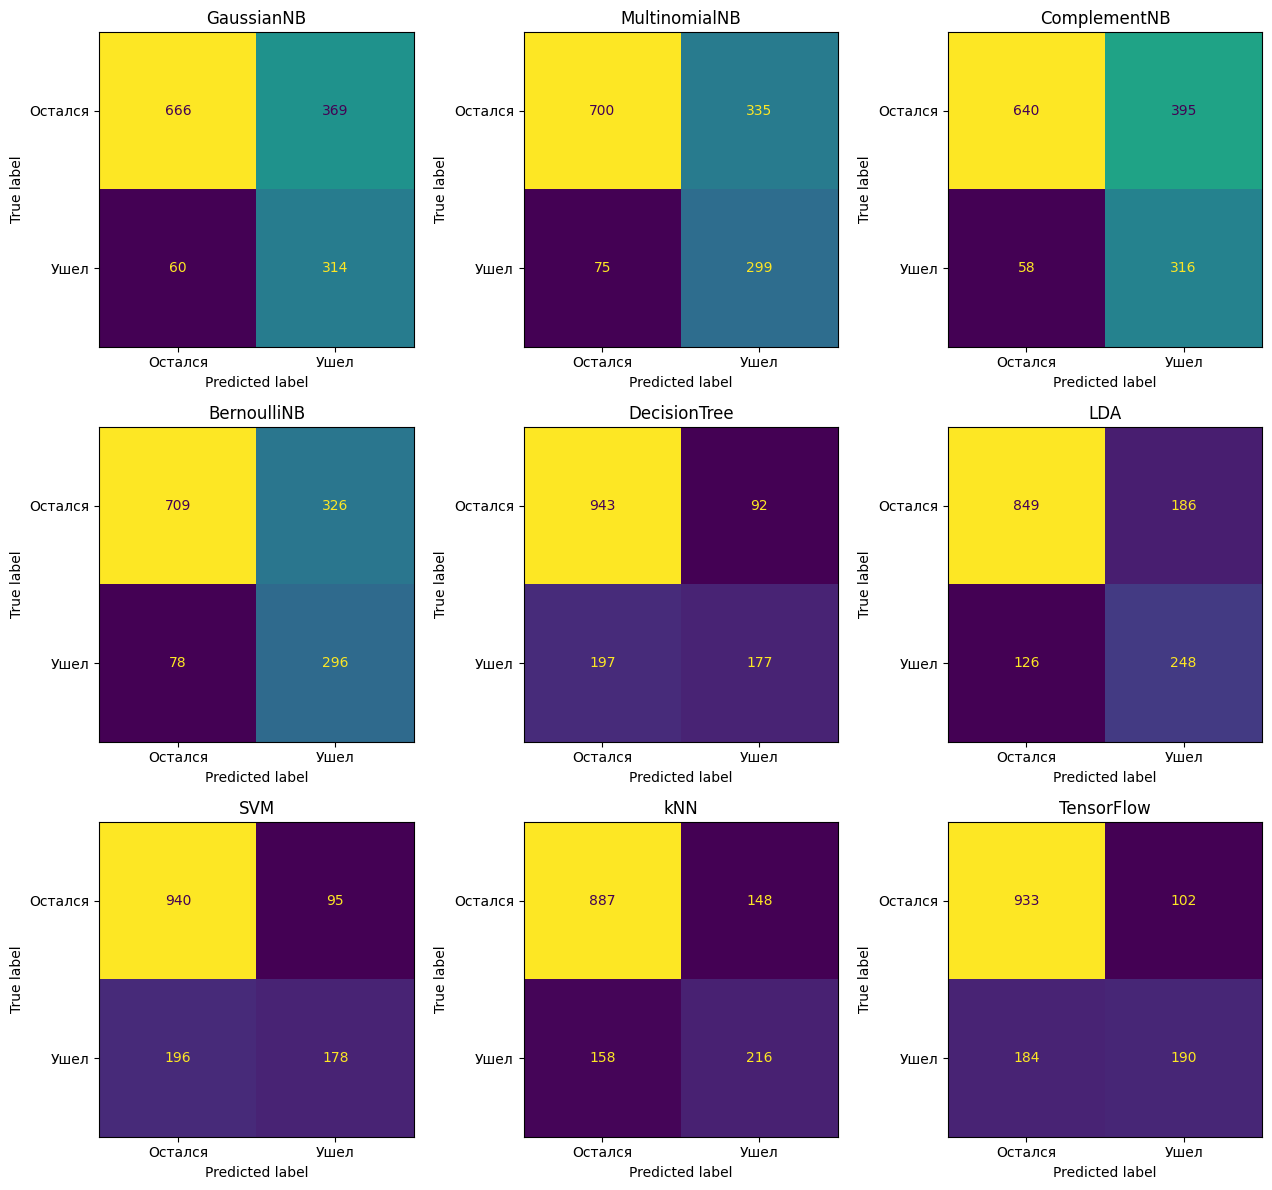

In [9]:
def measures(truth, pred, score):
    return {'Accuracy':accuracy_score(truth,pred),'Precision':precision_score(truth,pred,zero_division=0),
            'Recall':recall_score(truth,pred,zero_division=0),'F1':f1_score(truth,pred,zero_division=0),
            'ROC-AUC':roc_auc_score(truth,score)}
rows, scores, predictions = [], {}, {}
for name, search in searches.items():
    for variant, estimator in [('исходная',baselines[name].best_estimator_),('настроенная',search.best_estimator_)]:
        pred = estimator.predict(X_test)
        score = estimator.decision_function(X_test) if name=='SVM' else estimator.predict_proba(X_test)[:,1]
        rows.append({'Метод':name,'Вариант':variant,**measures(y_test,pred,score)})
        if variant=='настроенная': scores[name]=score; predictions[name]=pred
dummy = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
rows.append({'Метод':'Majority','Вариант':'контроль',**measures(y_test,dummy.predict(X_test),dummy.predict_proba(X_test)[:,1])})
p_nn = best_nn.predict(dataset(a_test,batch=128),verbose=0).ravel()
scores['TensorFlow']=p_nn; predictions['TensorFlow']=(p_nn>=.5).astype(int)
rows.append({'Метод':'TensorFlow','Вариант':best_nn_name,**measures(y_test,predictions['TensorFlow'],p_nn)})
results = pd.DataFrame(rows)
display(results.round(4)); results.to_csv(ART/'test_metrics.csv',index=False)
final = results[results['Вариант']!='исходная'].set_index('Метод')
fig, axes = plt.subplots(2,3,figsize=(17,9))
for ax,metric in zip(axes.ravel(),['Accuracy','Precision','Recall','F1','ROC-AUC']):
    final[metric].plot.bar(ax=ax,ylim=(0,1),title=metric,rot=65)
    ax.grid(axis='y',alpha=.2)
axes.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()
plt.figure(figsize=(9,7))
for name,score in scores.items():
    fpr,tpr,_ = roc_curve(y_test,score)
    plt.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(y_test,score):.3f})')
plt.plot([0,1],[0,1],'k--',label='Случайное ранжирование')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC-кривые на тестовой выборке')
plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.show()
fig,axes = plt.subplots(3,3,figsize=(13,12))
for ax,(name,pred) in zip(axes.ravel(),predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Остался','Ушел'],ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()


In [10]:
leader = final['ROC-AUC'].idxmax()
best_f1 = final['F1'].idxmax()
cv_leader = max(searches,key=lambda k: searches[k].best_score_)
display(Markdown(f"""### Интерпретация результатов
Наибольший тестовый ROC-AUC среди рассмотренных протоколов: **{leader}** ({final.loc[leader,'ROC-AUC']:.4f}); лучший тестовый F1: **{best_f1}** ({final.loc[best_f1,'F1']:.4f}).
Среди классических моделей по CV заранее выбран **{cv_leader}** (CV AUC={searches[cv_leader].best_score_:.4f}).
Для него на тесте Precision={final.loc[cv_leader,'Precision']:.4f}, Recall={final.loc[cv_leader,'Recall']:.4f}, F1={final.loc[cv_leader,'F1']:.4f}.

Если задача — ранжировать клиентов для программы удержания, предпочтителен высокий ROC-AUC; если важна полнота обнаружения ухода, необходимо сравнивать Recall и стоимость ложных срабатываний. Высокий AUC не гарантирует высокий Recall при фиксированном пороге. Приоритетом выбора для внедрения остается CV/validation, а не повторный подбор по тесту.

Результаты относятся к одному разбиению и ограниченным сеткам. Небольшие различия не доказывают превосходства: нужны повторная вложенная CV или доверительные интервалы. Четыре варианта NB имеют разные предположения; в частности, платежи не являются счетчиками и ограничивают естественную интерпретацию Multinomial/Complement NB. Нейросеть требует больше настроек, а ее превосходство над классическими моделями нельзя предполагать заранее.
"""))


### Интерпретация результатов
Наибольший тестовый ROC-AUC среди рассмотренных протоколов: **TensorFlow** (0.8436); лучший тестовый F1: **LDA** (0.6139).
Среди классических моделей по CV заранее выбран **LDA** (CV AUC=0.8410).
Для него на тесте Precision=0.5714, Recall=0.6631, F1=0.6139.

Если задача — ранжировать клиентов для программы удержания, предпочтителен высокий ROC-AUC; если важна полнота обнаружения ухода, необходимо сравнивать Recall и стоимость ложных срабатываний. Высокий AUC не гарантирует высокий Recall при фиксированном пороге. Приоритетом выбора для внедрения остается CV/validation, а не повторный подбор по тесту.

Результаты относятся к одному разбиению и ограниченным сеткам. Небольшие различия не доказывают превосходства: нужны повторная вложенная CV или доверительные интервалы. Четыре варианта NB имеют разные предположения; в частности, платежи не являются счетчиками и ограничивают естественную интерпретацию Multinomial/Complement NB. Нейросеть требует больше настроек, а ее превосходство над классическими моделями нельзя предполагать заранее.


### Обсуждение выполненного эксперимента
**Рекомендация для ранжирования:** выбранная по validation сеть с одним скрытым слоем из 32 нейронов и `tanh` (validation AUC 0,8511). На тесте AUC 0,8436, Accuracy 0,7970. Среди классических моделей LDA выбран по CV (0,8410) и получил тестовый AUC 0,8347. Разница тестовых AUC около 0,009 не доказывает статистически значимого превосходства сети. LDA проще в обучении и при штатном пороге дает лучший F1 (0,6139 против 0,5706 у сети), а также Recall 0,6631 против 0,5080. Поэтому для обнаружения уходящих клиентов при фиксированном пороге LDA является более удачным компромиссом на этом разбиении.

**Влияние параметров:** ограничение дерева глубиной 6 и листом не менее 50 клиентов повысило тестовый AUC с 0,6549 до 0,8326: исходное глубокое дерево переобучалось. У kNN увеличение числа соседей до 65 и равномерное голосование повысили тестовый AUC с 0,7880 до 0,8297. Для SVM лучшим на CV стало RBF-ядро с C=0,1 и gamma=0,01, на тесте AUC повысился с 0,7932 до 0,8316. У NB сглаживание изменяет качество слабо: предположение независимости плохо согласуется с взаимосвязанными услугами и платежами. Высокий Recall ComplementNB (0,8449) сопровождается низким Precision (0,4444), то есть многими ложными тревогами.

**Нейросеть:** лимиты 10, 30 и 60 эпох дали одинаковые восстановленные веса базы: минимум validation loss достигнут на 10-й эпохе, при больших лимитах остановка произошла на 17-й. Продление обучения не помогло. Батч 128 дал validation AUC 0,8499 против 0,8497 базы; увеличение ширины до 64 и добавление второго слоя дали 0,8483 и 0,8487. Усложнение сети не улучшило результат. `tanh` дал 0,8511; выигрыш мал и требует проверки на других seed. Изменение архитектуры меняет и число обучаемых параметров, поэтому сравнение отражает конкретные конфигурации, а не универсальное свойство активации.

Контроль большинства получил Accuracy 0,7346, но Recall=F1=0 и AUC=0,5: это наглядно показывает, почему одной Accuracy недостаточно.


## 8. Заключение
Выполнена бинарная классификация оттока: проверены идентификаторы и пропуски, реализованы безопасные Pipeline, стратифицированное разбиение и CV. Сравнены GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, дерево, LDA, SVM и kNN. Для каждого метода исследована сетка параметров с фиксацией среднего CV AUC и разброса; исходные и настроенные варианты оценены на общем тесте.

Реализована сеть TensorFlow с sigmoid-выходом, binary cross-entropy и Adam. Отдельно изменены число эпох, батч, ширина, глубина и активация. Представлены фактические эпохи, графики train/validation и журналы TensorBoard. Конкретные лидеры и значения метрик приведены в предыдущей ячейке и CSV, а не заданы заранее.

Развитие работы: повторная оценка на нескольких seed, анализ стоимости ошибок и выбор порога на validation, калибровка вероятностей. Для реального применения требуется внешняя проверка на новых клиентах; демографические признаки требуют отдельного анализа справедливости.

### Источники
1. IBM Telco Customer Churn — предоставленный CSV `WA_Fn-UseC_-Telco-Customer-Churn.csv`.
2. [Scikit-Learn User Guide](https://scikit-learn.org/stable/user_guide.html).
3. [TensorFlow: классификация структурированных данных](https://www.tensorflow.org/tutorials/structured_data/preprocessing_layers).
4. [TensorBoard: начало работы](https://www.tensorflow.org/tensorboard/get_started).
